In [1]:
import numpy as np
import statsmodels.api as sm
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, LogNorm
from pathlib import Path
import locale
import pickle
import yaml

In [2]:
from setup import (
    violet,
    blue,
    green,
    yellow,
    orange,
    red,
    white,
    gray,
    black,
    colors,
    plot_style,
    filepath,
    configuration,
    testing_labels,
    spectral_range,
    testing_settling_time as settling_time,
    calibration_type,
    predictor_type,
)
from processing import (
    is_system_settled,
    scaling_from_pid_to_cell,
    annotate,
    cm2inch,
    format_number,
)

In [3]:
locale.setlocale(locale.LC_ALL, "en_US.UTF-8")

plt.style.use(plot_style)
plt.rcParams.update(
    {
        "font.size": 8,
        "axes.titlesize": 10,
        "axes.labelsize": 9,
        "xtick.labelsize": 8,
        "ytick.labelsize": 8,
        "legend.fontsize": 8,
        "lines.linewidth": 0.7,
        "patch.linewidth": 0.7,
        "lines.markeredgewidth": 0.7,
        "lines.markersize": 3.5,
        "axes.formatter.use_locale": True,
    }
)

### Load testing datasets

In [4]:
times = []
voltages = []
absorbances = []
flowrates = []
setpoints = []
are_settled = []
are_analyte_free = []

wavenumber = None
spectral_resolution = None
gas_1 = None
gas_2 = None
split_ratio = None
window_type = None
correction_type = None
signal_type = None

if predictor_type != "absorbance":
    raise ValueError(f"Unsupported predictor type: {predictor_type}.")

for label in testing_labels:
    dataset = np.load(filepath / f"{label}.npz")
    metadata = yaml.safe_load((filepath / f"{label}.yaml").read_text())

    if spectral_resolution is None:
        spectral_resolution = metadata["sampling"]["spectral_resolution"]
    elif spectral_resolution != metadata["sampling"]["spectral_resolution"]:
        raise ValueError(f"Spectral resolution mismatch for {label}.")

    time = dataset["time"]
    spectrum = dataset["spectrum"]

    if wavenumber is None:
        wavenumber = dataset["wavenumber"]
        spectral_mask = (wavenumber >= spectral_range[0]) & (
            wavenumber <= spectral_range[1]
        )
    elif wavenumber.shape != dataset["wavenumber"].shape:
        raise ValueError(f"Wavenumber mismatch for {label}.")
    elif not np.allclose(wavenumber, dataset["wavenumber"], atol=1e-3):
        raise ValueError(f"Wavenumber mismatch for {label}.")

    if gas_1 is None:
        gas_1 = str(dataset["gas_1"])
    elif gas_1 != str(dataset["gas_1"]):
        raise ValueError(f"Gas 1 mismatch for {label}.")

    if gas_2 is None:
        gas_2 = str(dataset["gas_2"])
    elif gas_2 != str(dataset["gas_2"]):
        raise ValueError(f"Gas 2 mismatch for {label}.")

    if split_ratio is None:
        split_ratio = float(dataset["split_ratio"])
    elif split_ratio != float(dataset["split_ratio"]):
        raise ValueError(f"Split ratio mismatch for {label}.")

    if dataset["type"] == "twins":
        if window_type is None:
            window_type = str(dataset["window_type"])
        elif window_type != str(dataset["window_type"]):
            raise ValueError(f"Window type mismatch for {label}.")

        if correction_type is None:
            correction_type = str(dataset["correction_type"])
        elif correction_type != str(dataset["correction_type"]):
            raise ValueError(f"Correction type mismatch for {label}.")

        if signal_type is None:
            signal_type = str(dataset["signal_type"])
        elif signal_type != str(dataset["signal_type"]):
            raise ValueError(f"Signal type mismatch for {label}.")

    setpoint_0 = dataset["setpoint_0"]
    setpoint_1 = dataset["setpoint_1"]
    setpoint_2 = dataset["setpoint_2"]
    setpoint = np.stack(
        [
            np.mean(setpoint_0, axis=1),
            np.mean(setpoint_1, axis=1),
            np.mean(setpoint_2, axis=1),
        ],
        axis=1,
    )

    flowrate_0 = dataset["flowrate_0"]
    flowrate_1 = dataset["flowrate_1"]
    flowrate_2 = dataset["flowrate_2"]
    flowrate = np.stack(
        [
            np.mean(flowrate_0, axis=1),
            np.mean(flowrate_1, axis=1),
            np.mean(flowrate_2, axis=1),
        ],
        axis=1,
    )

    voltage_pid_1 = dataset["voltage_pid_1"] / 1e6  # (V)
    voltage_pid_2 = dataset["voltage_pid_2"] / 1e6  # (V)
    voltage = np.stack(
        [np.mean(voltage_pid_1, axis=1), np.mean(voltage_pid_2, axis=1)],
        axis=1,
    )

    time_offset = np.max(np.concatenate(times)) if times else 0
    time = np.min(time, axis=1) + time_offset

    spectrum = spectrum[:, spectral_mask]

    is_settled = is_system_settled(time, setpoint_1, setpoint_2, settling_time)
    is_analyte_free = (
        np.all((setpoint_0 != 0) & (setpoint_1 == 0) & (setpoint_2 == 0), axis=1)
        & is_settled
    )

    if not np.any(is_analyte_free):
        raise ValueError(f"No analyte-free spectra found for {label}.")

    absorbance = -np.log10(spectrum / np.mean(spectrum[is_analyte_free, :], axis=0))

    times.append(time)
    voltages.append(voltage)
    absorbances.append(absorbance)
    flowrates.append(flowrate)
    setpoints.append(setpoint)
    are_settled.append(is_settled)
    are_analyte_free.append(is_analyte_free)

times = np.concatenate(times, axis=0)
voltages = np.concatenate(voltages, axis=0)
absorbances = np.concatenate(absorbances, axis=0)
flowrates = np.concatenate(flowrates, axis=0)
setpoints = np.concatenate(setpoints, axis=0)
are_settled = np.concatenate(are_settled, axis=0)
are_analyte_free = np.concatenate(are_analyte_free, axis=0)

gases = (gas_1, gas_2)
wavenumber = wavenumber[spectral_mask]

In [5]:
number_spectra, number_wavenumbers = np.shape(absorbances)
number_gases = len(gases)
gas_pair = "-".join(gas.lower() for gas in gases)
gas_labels = {"isopropanol": "iPrOH", "ethanol": "EtOH"}

print(f"Datasets: {', '.join(testing_labels)}")
print(f"Gases: {gas_labels[gas_1]}, {gas_labels[gas_2]}")
print(
    f"Spectra: {number_spectra} "
    f"({np.sum(are_settled)} are settled, {np.sum(are_analyte_free)} are analyte free)"
)
print(f"Wavenumbers: {number_wavenumbers} at {spectral_resolution} cm^-1 resolution")

Datasets: GRASP26_72F
Gases: iPrOH, EtOH
Spectra: 882 (402 are settled, 210 are analyte free)
Wavenumbers: 30 at 20 cm^-1 resolution


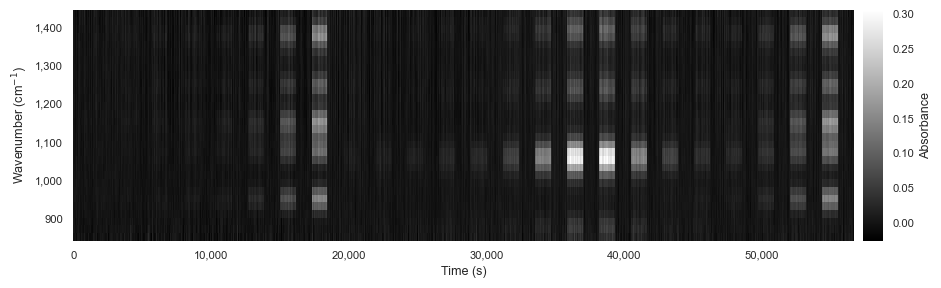

In [6]:
fig, ax = plt.subplots(figsize=(12, 3))

mesh = ax.pcolormesh(
    times,
    wavenumber,
    absorbances.T,
    cmap="gray",
)

ax.set_xlabel("Time (s)")
ax.set_ylabel("Wavenumber (cm$^{-1}$)")

fig.colorbar(mesh, ax=ax, label="Absorbance", aspect=12, pad=0.01)

### Load calibrated concentrations

In [7]:
concentrations = []
cutoff_concentrations = []
scalings_pid_to_cell = []
for ii, gas in enumerate(gases):
    with open(Path("models", f"estimator-{gas.lower()}.pkl"), "rb") as file:
        calibration = pickle.load(file)

    concentration_estimator = calibration["estimator"]

    if calibration_type == "flowrate":
        concentration = concentration_estimator(flowrates[:, ii + 1])
    elif calibration_type == "pid":
        scaling_pid_to_cell = scaling_from_pid_to_cell(flowrates, split_ratio, ii + 1)
        concentration = scaling_pid_to_cell * concentration_estimator(voltages[:, ii])

        cutoff_concentrations.append(calibration["cutoff_concentration"])
        scalings_pid_to_cell.append(scaling_pid_to_cell)

    concentrations.append(concentration)

concentrations = np.stack(concentrations, axis=1)
if calibration_type == "pid":
    cutoff_concentrations = np.array(cutoff_concentrations)
    scalings_pid_to_cell = np.stack(scalings_pid_to_cell, axis=1)

### Define selection mask

In [8]:
selection_mask = are_settled
if calibration_type == "pid":
    selection_mask = selection_mask & np.all(
        concentrations < cutoff_concentrations * scalings_pid_to_cell,
        axis=1,
    )

### Load regression model

In [9]:
with open(Path("models", f"ridge-{gas_pair}.pkl"), "rb") as file:
    model = pickle.load(file)

model_weights = model.named_steps["model"].coef_.T

concentration_predictions = model.predict(absorbances)

c:\Users\eherkert\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\base.py:380: InconsistentVersionWarning: Trying to unpickle estimator FunctionTransformer from version 1.9.1 when using version 1.6.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
c:\Users\eherkert\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\base.py:380: InconsistentVersionWarning: Trying to unpickle estimator StandardScaler from version 1.9.1 when using version 1.6.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
c:\Users\eherkert\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\base.py:380: InconsistentVersionWarning: Trying to un

### Filter model predictions

In [10]:
with open(Path("models", f"kalman-{gas_pair}.pkl"), "rb") as file:
    kalman_filter = pickle.load(file)

In [11]:
concentrations_filtered = np.zeros_like(concentration_predictions)

for ii in range(number_spectra):
    kalman_filter.predict()
    kalman_filter.update(concentration_predictions[ii, :])

    concentrations_filtered[ii, :] = kalman_filter.x

### Plot performance characterization

In [12]:
only_isopropanol_mask = selection_mask & (setpoints[:, 1] != 0) & (setpoints[:, 2] == 0)
only_ethanol_mask = selection_mask & (setpoints[:, 2] != 0) & (setpoints[:, 1] == 0)
analyte_free_mask = are_analyte_free

In [13]:
x = np.concatenate(
    [concentrations[selection_mask, :], np.ones((selection_mask.sum(), 1))], axis=1
)
y = concentrations_filtered[selection_mask, :]
fits = [sm.OLS(y[:, ii], x).fit() for ii in range(number_gases)]

s_11, s_12, b_1 = fits[0].params
s_11, s_12, b_1 = fits[0].params
s_21, s_22, b_2 = fits[1].params
s_21, s_22, b_2 = fits[1].params

s_11_se, s_12_se, b_1_se = fits[0].bse
s_11_se, s_12_se, b_1_se = fits[0].bse
s_21_se, s_22_se, b_2_se = fits[1].bse
s_21_se, s_22_se, b_2_se = fits[1].bse

In [14]:
x = np.concatenate(
    [
        times[analyte_free_mask, None],
        np.ones((analyte_free_mask.sum(), 1)),
    ],
    axis=1,
)
y = concentrations_filtered[analyte_free_mask, :]

fits = [sm.OLS(y[:, ii], x).fit() for ii in range(number_gases)]

d_1, _ = fits[0].params
d_2, _ = fits[1].params

d_1_se, _ = fits[0].bse
d_2_se, _ = fits[1].bse

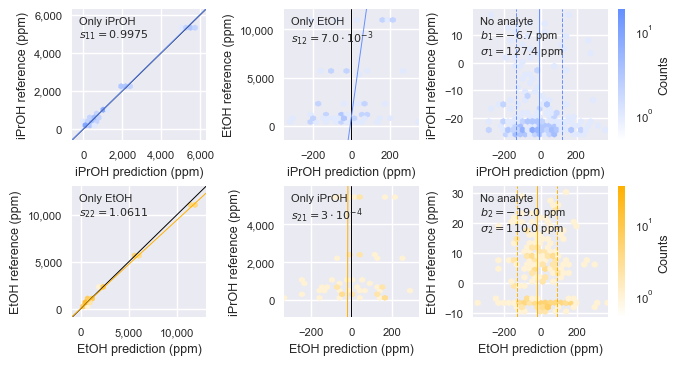

In [15]:
fig, axs = plt.subplots(
    2,
    3,
    figsize=cm2inch((17, 9)),
    constrained_layout=True,
)

number_columns = axs.shape[1]

### density colormaps ###
colormap_isopropanol = LinearSegmentedColormap.from_list("white_to_blue", [white, blue])
colormap_ethanol = LinearSegmentedColormap.from_list("white_to_yellow", [white, yellow])

hexbin_kwargs = {
    "gridsize": 25,
    "mincnt": 1,
    "zorder": 5,
}


### isopropanol sensitivity plot ###
concentrations_predicted = concentrations_filtered[only_isopropanol_mask, 0]
concentrations_reference = concentrations[only_isopropanol_mask, 0]

c_min = np.min((concentrations_predicted.min(), concentrations_reference.min()))
c_max = np.max((concentrations_predicted.max(), concentrations_reference.max()))
c_lim = np.array([c_min - 0.1 * (c_max - c_min), c_max + 0.1 * (c_max - c_min)])

hexbin_sensitivity_isopropanol = axs[0, 0].hexbin(
    concentrations_predicted,
    concentrations_reference,
    cmap=colormap_isopropanol,
    extent=(c_min, c_max, c_min, c_max),
    **hexbin_kwargs,
)

axs[0, 0].plot(
    c_lim,
    c_lim,
    color=black,
    zorder=10,
)


axs[0, 0].plot(
    s_11 * c_lim + b_1,
    c_lim,
    color=blue,
    zorder=15,
)

axs[0, 0].set_xlim(*c_lim)
axs[0, 0].set_ylim(*c_lim)
axs[0, 0].set_xlabel("iPrOH prediction (ppm)")
axs[0, 0].set_ylabel("iPrOH reference (ppm)")

annotate(
    axs[0, 0],
    f"Only iPrOH\n$s_{{11}} = {format_number(s_11, s_11_se)}$",
)

### isopropanol cross-sensitivity plot ###
concentrations_predicted = concentrations_filtered[only_ethanol_mask, 0]
concentrations_reference = concentrations[only_ethanol_mask, 1]

c_min = np.min((concentrations_predicted.min(), concentrations_reference.min()))
c_max = np.max((concentrations_predicted.max(), concentrations_reference.max()))
c_lim = np.array([c_min - 0.1 * (c_max - c_min), c_max + 0.1 * (c_max - c_min)])

hexbin_cross_sensitivity_isopropanol = axs[0, 1].hexbin(
    concentrations_predicted,
    concentrations_reference,
    cmap=colormap_isopropanol,
    **hexbin_kwargs,
)

axs[0, 1].axvline(0, color=black, zorder=10)

axs[0, 1].plot(
    s_12 * c_lim + b_1,
    c_lim,
    color=blue,
    zorder=15,
)

axs[0, 1].set_xlim(
    -np.max(np.abs(concentrations_predicted)), np.max(np.abs(concentrations_predicted))
)
axs[0, 1].set_ylim(*c_lim)
axs[0, 1].set_xlabel("iPrOH prediction (ppm)")
axs[0, 1].set_ylabel("EtOH reference (ppm)")

annotate(
    axs[0, 1],
    f"Only EtOH\n$s_{{12}} = {format_number(s_12, s_12_se)}$",
)

### isopropanol bias plot ###
concentrations_predicted = concentrations_filtered[analyte_free_mask, 0]
concentrations_reference = concentrations[analyte_free_mask, 0]

sigma_1 = np.std(concentrations_predicted, ddof=1)
sigma_1_se = sigma_1 / np.sqrt(2 * (sum(analyte_free_mask) - 1))

hexbin_bias_isopropanol = axs[0, 2].hexbin(
    concentrations_predicted,
    concentrations_reference,
    cmap=colormap_isopropanol,
    **hexbin_kwargs,
)

axs[0, 2].axvline(b_1, color=blue, zorder=10)
axs[0, 2].axvline(b_1 + sigma_1, color=blue, linestyle="--", zorder=10)
axs[0, 2].axvline(b_1 - sigma_1, color=blue, linestyle="--", zorder=10)

axs[0, 2].margins(0.05, 0.05)
axs[0, 2].set_xlim(
    -np.max(np.abs(concentrations_predicted)), np.max(np.abs(concentrations_predicted))
)
axs[0, 2].set_xlabel("iPrOH prediction (ppm)")
axs[0, 2].set_ylabel("iPrOH reference (ppm)")

annotate(
    axs[0, 2],
    f"No analyte\n$b_1 = {format_number(b_1, b_1_se)}$ ppm\n$\\sigma_1 = {format_number(sigma_1, sigma_1_se)}$ ppm",
)

### ethanol sensitivity plot ###
concentrations_predicted = concentrations_filtered[only_ethanol_mask, 1]
concentrations_reference = concentrations[only_ethanol_mask, 1]

c_min = np.min((concentrations_predicted.min(), concentrations_reference.min()))
c_max = np.max((concentrations_predicted.max(), concentrations_reference.max()))
c_lim = np.array([c_min - 0.1 * (c_max - c_min), c_max + 0.1 * (c_max - c_min)])

hexbin_sensitivity_ethanol = axs[1, 0].hexbin(
    concentrations_predicted,
    concentrations_reference,
    cmap=colormap_ethanol,
    extent=(c_min, c_max, c_min, c_max),
    **hexbin_kwargs,
)

axs[1, 0].plot(
    c_lim,
    c_lim,
    color=black,
    zorder=10,
)

axs[1, 0].plot(
    s_22 * c_lim + b_2,
    c_lim,
    color=yellow,
    zorder=15,
)

axs[1, 0].set_xlim(*c_lim)
axs[1, 0].set_ylim(*c_lim)
axs[1, 0].set_xlabel("EtOH prediction (ppm)")
axs[1, 0].set_ylabel("EtOH reference (ppm)")

annotate(
    axs[1, 0],
    f"Only EtOH\n$s_{{22}} = {format_number(s_22, s_22_se)}$",
)

### ethanol cross-sensitivity plot ###
concentrations_predicted = concentrations_filtered[only_isopropanol_mask, 1]
concentrations_reference = concentrations[only_isopropanol_mask, 0]

c_min = np.min((concentrations_predicted.min(), concentrations_reference.min()))
c_max = np.max((concentrations_predicted.max(), concentrations_reference.max()))
c_lim = np.array([c_min - 0.1 * (c_max - c_min), c_max + 0.1 * (c_max - c_min)])

hexbin_cross_sensitivity_ethanol = axs[1, 1].hexbin(
    concentrations_predicted,
    concentrations_reference,
    cmap=colormap_ethanol,
    **hexbin_kwargs,
)

axs[1, 1].axvline(0, color=black, zorder=10)

axs[1, 1].plot(
    s_21 * c_lim + b_2,
    c_lim,
    color=yellow,
    zorder=15,
)

axs[1, 1].set_xlim(
    -np.max(np.abs(concentrations_predicted)), np.max(np.abs(concentrations_predicted))
)
axs[1, 1].set_ylim(*c_lim)
axs[1, 1].set_xlabel("EtOH prediction (ppm)")
axs[1, 1].set_ylabel("iPrOH reference (ppm)")

annotate(
    axs[1, 1],
    f"Only iPrOH\n$s_{{21}} = {format_number(s_21, s_21_se)}$",
)

### ethanol bias plot ###
concentrations_predicted = concentrations_filtered[analyte_free_mask, 1]
concentrations_reference = concentrations[analyte_free_mask, 1]

sigma_2 = np.std(concentrations_predicted, ddof=1)
sigma_2_se = sigma_2 / np.sqrt(2 * (sum(analyte_free_mask) - 1))

hexbin_bias_ethanol = axs[1, 2].hexbin(
    concentrations_predicted,
    concentrations_reference,
    cmap=colormap_ethanol,
    **hexbin_kwargs,
)

axs[1, 2].axvline(b_2, color=yellow, zorder=10)
axs[1, 2].axvline(b_2 + sigma_2, color=yellow, linestyle="--", zorder=10)
axs[1, 2].axvline(b_2 - sigma_2, color=yellow, linestyle="--", zorder=10)

axs[1, 2].margins(0.05, 0.05)
axs[1, 2].set_xlim(
    -np.max(np.abs(concentrations_predicted)), np.max(np.abs(concentrations_predicted))
)
axs[1, 2].set_xlabel("EtOH prediction (ppm)")
axs[1, 2].set_ylabel("EtOH reference (ppm)")

annotate(
    axs[1, 2],
    f"No analyte\n$b_2 = {format_number(b_2, b_2_se)}$ ppm\n$\\sigma_2 = {format_number(sigma_2, sigma_2_se)}$ ppm",
)

### isopropanol count scale ###
hexbins_isopropanol = (
    hexbin_sensitivity_isopropanol,
    hexbin_cross_sensitivity_isopropanol,
    hexbin_bias_isopropanol,
)

count_maximum_isopropanol = np.max(
    [hexbin.get_array().max() for hexbin in hexbins_isopropanol]
)
normalization_isopropanol = LogNorm(vmin=0.5, vmax=2 * count_maximum_isopropanol)

for hexbin in hexbins_isopropanol:
    hexbin.set_norm(normalization_isopropanol)

fig.colorbar(
    hexbin_sensitivity_isopropanol,
    ax=axs[0, :],
    location="right",
    label="Counts",
    aspect=20,
    pad=0.02,
)

### ethanol count scale ###
hexbins_ethanol = (
    hexbin_sensitivity_ethanol,
    hexbin_cross_sensitivity_ethanol,
    hexbin_bias_ethanol,
)

count_maximum_ethanol = np.max([hexbin.get_array().max() for hexbin in hexbins_ethanol])
normalization_ethanol = LogNorm(vmin=0.5, vmax=2 * count_maximum_ethanol)

for hexbin in hexbins_ethanol:
    hexbin.set_norm(normalization_ethanol)

fig.colorbar(
    hexbin_sensitivity_ethanol,
    ax=axs[1, :],
    location="right",
    label="Counts",
    aspect=20,
    pad=0.02,
)

filepath = Path("..", "Figures", f"04-sensitivity-characterization-{configuration}.svg")
fig.savefig(filepath, dpi=600)

In [16]:
print(
    f"Sensitivity (s_11): "
    f"{format_number(s_11, s_11_se)} +/- {format_number(s_11_se, s_11_se)}"
)
print(
    f"Sensitivity (s_22): "
    f"{format_number(s_22, s_22_se)} +/- {format_number(s_22_se, s_22_se)}"
)
print()

print(
    f"Cross-sensitivity (s_12): "
    f"{format_number(s_12, s_12_se)} +/- {format_number(s_12_se, s_12_se)}"
)
print(
    f"Cross-sensitivity (s_21): "
    f"{format_number(s_21, s_21_se)} +/- {format_number(s_21_se, s_21_se)}"
)
print()


k = 1
r_1 = (np.abs(s_11)) / (np.abs(s_12))
r_2 = (np.abs(s_22)) / (np.abs(s_21))
r_1_bound = (np.abs(s_11) - k * s_11_se) / (np.abs(s_12) + k * s_12_se)
r_2_bound = (np.abs(s_22) - k * s_22_se) / (np.abs(s_21) + k * s_21_se)
print(f"Selectivity (s_11 / s_12): {r_1:.0f} (>{r_1_bound:.0f})")
print(f"Selectivity (s_22 / s_21): {r_2:.0f} (>{r_2_bound:.0f})")
print()

print(
    f"Variance (sigma_1): "
    f"{format_number(sigma_1, sigma_1_se)} +/- "
    f"{format_number(sigma_1_se, sigma_1_se)} ppm"
)
print(
    f"Variance (sigma_2): "
    f"{format_number(sigma_2, sigma_2_se)} +/- "
    f"{format_number(sigma_2_se, sigma_2_se)} ppm"
)
print()

LOD_1 = 3 * sigma_1 / s_11
LOD_1_se = LOD_1 * np.sqrt(sigma_1_se**2 / sigma_1**2 + s_11_se**2 / s_11**2)
LOD_2 = 3 * sigma_2 / s_22
LOD_2_se = LOD_2 * np.sqrt(sigma_2_se**2 / sigma_2**2 + s_22_se**2 / s_22**2)

print(
    f"LOD (3 * sigma_1 / s_11): "
    f"{format_number(LOD_1, LOD_1_se)} +/- "
    f"{format_number(LOD_1_se, LOD_1_se)} ppm"
)
print(
    f"LOD (3 * sigma_2 / s_22): "
    f"{format_number(LOD_2, LOD_2_se)} +/- "
    f"{format_number(LOD_2_se, LOD_2_se)} ppm"
)
print()


print(
    f"Bias (b_1): {format_number(b_1, b_1_se)} +/- {format_number(b_1_se, b_1_se)} ppm"
)
print(
    f"Bias (b_2): {format_number(b_2, b_2_se)} +/- {format_number(b_2_se, b_2_se)} ppm"
)
print()

print(
    f"Drift (d_1): "
    f"{format_number(d_1 * 3_600, d_1_se * 3_600)} +/- {format_number(d_1_se * 3_600, d_1_se * 3_600)} ppm/h"
)
print(
    f"Drift (d_2): "
    f"{format_number(d_2 * 3_600, d_2_se * 3_600)} +/- {format_number(d_2_se * 3_600, d_2_se * 3_600)} ppm/h"
)
print()

Sensitivity (s_11): 0.9975 +/- 6.0\cdot10^{-3}
Sensitivity (s_22): 1.0611 +/- 2.8\cdot10^{-3}

Cross-sensitivity (s_12): 7.0\cdot10^{-3} +/- 2.9\cdot10^{-3}
Cross-sensitivity (s_21): 3\cdot10^{-4} +/- 5.9\cdot10^{-3}

Selectivity (s_11 / s_12): 142 (>100)
Selectivity (s_22 / s_21): 3547 (>171)

Variance (sigma_1): 127.4 +/- 6.2 ppm
Variance (sigma_2): 110.0 +/- 5.4 ppm

LOD (3 * sigma_1 / s_11): 383 +/- 19 ppm
LOD (3 * sigma_2 / s_22): 311 +/- 15 ppm

Bias (b_1): -6.7 +/- 7.8 ppm
Bias (b_2): -19.0 +/- 7.7 ppm

Drift (d_1): -1.2 +/- 1.8 ppm/h
Drift (d_2): -1.3 +/- 1.6 ppm/h

